In [2]:
from datascience import *
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)

from urllib.request import urlopen 
import re
def read_url(url): 
    return re.sub('\\s+', ' ', urlopen(url).read().decode())

# Week 2 - Notebook 2: 2.2 & 2.3

## 2.2 Histograms

Histograms are a visual representation of the distribution of numerical (quantitative) data.
Characteristics of a histogram:
 * Data is separated into bins of equal width
    * The width is determined by subtracting the highest value from the lowest value and dividing by the number of desired bins. <br>
        $width =\dfrac{max - min}{\textit{number of bins}}$
 * Each bin accounts for all the possible values within the range of the bin
 * The bin values begin at the smaller bin range value and ends just before the larger bin value. [a,b)
 * In a frequency histogram, the height of a bar represents the frequency (quantity) of data in that bin. 
 * Bars are connected, there are no gaps between bins unless there is a bin with no data. 
 * Bars only tell us how much data is in a particular range, we cannot determine the frequency of a specific value from a histogram. 

Python command for Frequency Histograms: plots.hist(table.column(column_name), bins=(number_of_bins)

Explore the histogram command

In [3]:
plots.hist?

Signature:
plots.hist(
    x: 'ArrayLike | Sequence[ArrayLike]',
    bins: 'int | Sequence[float] | str | None' = None,
    *,
    range: 'tuple[float, float] | None' = None,
    density: 'bool' = False,
    weights: 'ArrayLike | None' = None,
    cumulative: 'bool | float' = False,
    bottom: 'ArrayLike | float | None' = None,
    histtype: "Literal['bar', 'barstacked', 'step', 'stepfilled']" = 'bar',
    align: "Literal['left', 'mid', 'right']" = 'mid',
    orientation: "Literal['vertical', 'horizontal']" = 'vertical',
    rwidth: 'float | None' = None,
    log: 'bool' = False,
    color: 'ColorType | Sequence[ColorType] | None' = None,
    label: 'str | Sequence[str] | None' = None,
    stacked: 'bool' = False,
    data=None,
    **kwargs,
) -> 'tuple[np.ndarray | list[np.ndarray], np.ndarray, BarContainer | Polygon | list[BarContainer | Polygon]]'
Docstring:
Compute and plot a histogram.

This method uses `numpy.histogram` to bin the data in *x* and count the
number of values in e

### Import Data 

***Run the next cell then describe the table:***
 * Content: Trip details for rentable scooters in Downtown San Francisco area. 
 * Variables:
 * Units for variables:
 * Quantitative Variables:
 * Qualitative Variables:
 * Other notable information: (how many records, etc)



In [4]:
trip = Table.read_table('trip.csv')
trip.show(15)

Trip ID,Duration,Start Date,Start Station,Start Terminal,End Date,End Station,End Terminal,Bike #,Subscriber Type,Zip Code
913460,765,8/31/2015 23:26,Harry Bridges Plaza (Ferry Building),50,8/31/2015 23:39,San Francisco Caltrain (Townsend at 4th),70,288,Subscriber,2139
913459,1036,8/31/2015 23:11,San Antonio Shopping Center,31,8/31/2015 23:28,Mountain View City Hall,27,35,Subscriber,95032
913455,307,8/31/2015 23:13,Post at Kearny,47,8/31/2015 23:18,2nd at South Park,64,468,Subscriber,94107
913454,409,8/31/2015 23:10,San Jose City Hall,10,8/31/2015 23:17,San Salvador at 1st,8,68,Subscriber,95113
913453,789,8/31/2015 23:09,Embarcadero at Folsom,51,8/31/2015 23:22,Embarcadero at Sansome,60,487,Customer,9069
913452,293,8/31/2015 23:07,Yerba Buena Center of the Arts (3rd @ Howard),68,8/31/2015 23:12,San Francisco Caltrain (Townsend at 4th),70,538,Subscriber,94118
913451,896,8/31/2015 23:07,Embarcadero at Folsom,51,8/31/2015 23:22,Embarcadero at Sansome,60,363,Customer,92562
913450,255,8/31/2015 22:16,Embarcadero at Sansome,60,8/31/2015 22:20,Steuart at Market,74,470,Subscriber,94111
913449,126,8/31/2015 22:12,Beale at Market,56,8/31/2015 22:15,Temporary Transbay Terminal (Howard at Beale),55,439,Subscriber,94130
913448,932,8/31/2015 21:57,Post at Kearny,47,8/31/2015 22:12,South Van Ness at Market,66,472,Subscriber,94702


***QUESTION: What questions could you answer with this data?***


***QUESTION: We will be focusing on the durations column, what questions could you answer specific to that variable?***


### Distribution of Durations ###

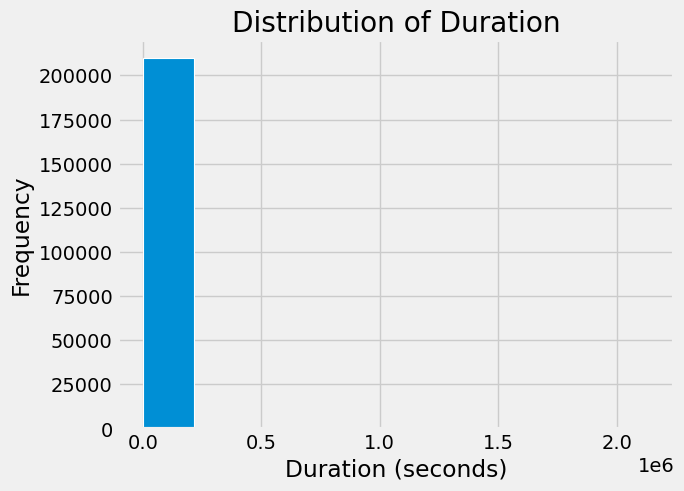

In [5]:
# --- Create Frequency Histogram ---
column_name = "Duration"          
unit = "seconds"                        

# Create a histogram of the Duration column using 10 bins. 
# Add these two arguments after specifying your bins to enhance the display. edgecolor="white", linewidth=0.8
plots.hist(
    trip.column(column_name),
    bins=10,                               
    edgecolor="white",
    linewidth=0.8
)

# Do not edit
plots.title(f"Distribution of {column_name}")
plots.xlabel(f"{column_name} ({unit})")
plots.ylabel("Frequency")
plots.show()

***QUESTION: Review the horizontal axis. Any guesses as to why the values are so high?***

Let's check the data...

In [6]:
trip.sort('Duration', descending=True)

Trip ID,Duration,Start Date,Start Station,Start Terminal,End Date,End Station,End Terminal,Bike #,Subscriber Type,Zip Code
825850,2137000,6/28/2015 21:50,Market at Sansome,77,7/23/2015 15:27,Yerba Buena Center of the Arts (3rd @ Howard),68,466,Customer,97213
750192,1852590,5/2/2015 6:17,San Antonio Shopping Center,31,5/23/2015 16:53,Castro Street and El Camino Real,32,680,Subscriber,94024
841176,1133540,7/10/2015 10:35,University and Emerson,35,7/23/2015 13:27,University and Emerson,35,262,Customer,94306
774999,688899,5/20/2015 15:27,Palo Alto Caltrain Station,34,5/28/2015 14:49,California Ave Caltrain Station,36,230,Customer,nil
635260,655939,2/8/2015 3:05,San Jose Civic Center,3,2/15/2015 17:17,SJSU 4th at San Carlos,12,132,Customer,89451
745640,611240,4/29/2015 9:41,University and Emerson,35,5/6/2015 11:28,San Antonio Shopping Center,31,196,Customer,81
635263,602338,2/8/2015 3:09,San Jose Civic Center,3,2/15/2015 2:28,San Jose Civic Center,3,9,Customer,89451
779645,594550,5/24/2015 13:33,San Pedro Square,6,5/31/2015 10:42,San Pedro Square,6,39,Customer,95118
812544,552697,6/18/2015 10:45,Mountain View Caltrain Station,28,6/24/2015 20:17,Palo Alto Caltrain Station,34,70,Customer,90024
661326,531240,2/27/2015 15:45,San Jose Diridon Caltrain Station,2,3/5/2015 19:19,SJSU 4th at San Carlos,12,662,Customer,95112


***QUESION: What could have caused those high duration values? (Remember, duration is in seconds.)***


Let's limit the duration to a realistic value. 

***QUESTION: Check the limit below, what is that in minutes?***


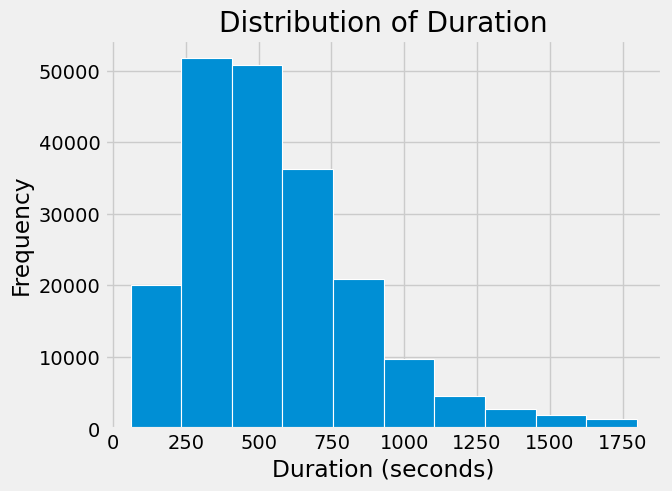

In [7]:
commute = trip.where('Duration', are.below(1800))

# --- Create Frequency Histogram ---
column_name = "Duration"            
unit = "seconds"                          

# Create a new histogram of the new Duration column using 10 bins. 
# Add these two arguments after specifying your bins to enhance the display. edgecolor="white", linewidth=0.8
plots.hist(
    commute.column(column_name),
    bins=10,                                # <-- Adjust number of bins as needed
    edgecolor="white",
    linewidth=0.8
)
# Do not edit
plots.title(f"Distribution of {column_name}")
plots.xlabel(f"{column_name} ({unit})")
plots.ylabel("Frequency")
plots.show()


***QUESTION: How would you describe the shape of the histogram? Determine your bin width.***

***QUESTION: What does that tell us about the data?***

***QUESTION: Would a different number of bins help us to see the data better?***

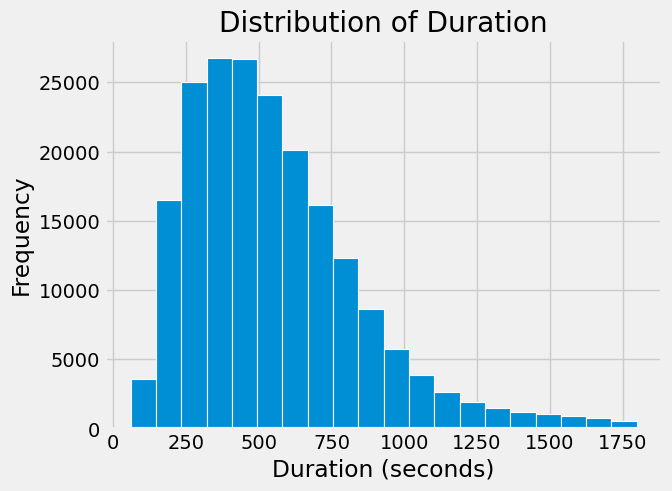

In [8]:
# Create a new histogram of the Duration column using 20 bins. 
# Add these two arguments after specifying your bins to enhance the display. edgecolor="white", linewidth=0.8
plots.hist(
    commute.column(column_name),
    bins= 20,                                
    edgecolor="white",
    linewidth=0.8
)
# Do not edit
plots.title(f"Distribution of {column_name}")
plots.xlabel(f"{column_name} ({unit})")
plots.ylabel("Frequency")
plots.show()

***Compare the Histograms***

The histogram above is the same data as the previous histogram but displayed differently.<br>
***QUESTION: What was changed and how was it changed? Determine your bin width.***

***QUESTION: Which view do you prefer and why?***

### Comparing the Distribution of Several Variables

We can display histograms for every variable in a table as long as each column is a quantitative variable.
    
Let's import a different data set since the majority of the numeric variables in the trip data are qualitative variables. 

#### Import Data

Import ckd.csv then describe the table:

   * Content: Test results for chronic kidney disease. Class 0: No disease, Class 1: Has disease. 
   * Variables:
   * Units for variables:
   * Quantitative Variables:
   * Qualitative Variables:
   * Other notable information: (how many records, etc)




In [9]:
ckd = Table.read_table('ckd.csv')
ckd

Age,Blood Pressure,Specific Gravity,Albumin,Sugar,Red Blood Cells,Pus Cell,Pus Cell clumps,Bacteria,Blood Glucose Random,Blood Urea,Serum Creatinine,Sodium,Potassium,Hemoglobin,Packed Cell Volume,White Blood Cell Count,Red Blood Cell Count,Hypertension,Diabetes Mellitus,Coronary Artery Disease,Appetite,Pedal Edema,Anemia,Class
48,70,1.005,4,0,normal,abnormal,present,notpresent,117,56,3.8,111,2.5,11.2,32,6700,3.9,yes,no,no,poor,yes,yes,1
53,90,1.02,2,0,abnormal,abnormal,present,notpresent,70,107,7.2,114,3.7,9.5,29,12100,3.7,yes,yes,no,poor,no,yes,1
63,70,1.01,3,0,abnormal,abnormal,present,notpresent,380,60,2.7,131,4.2,10.8,32,4500,3.8,yes,yes,no,poor,yes,no,1
68,80,1.01,3,2,normal,abnormal,present,present,157,90,4.1,130,6.4,5.6,16,11000,2.6,yes,yes,yes,poor,yes,no,1
61,80,1.015,2,0,abnormal,abnormal,notpresent,notpresent,173,148,3.9,135,5.2,7.7,24,9200,3.2,yes,yes,yes,poor,yes,yes,1
48,80,1.025,4,0,normal,abnormal,notpresent,notpresent,95,163,7.7,136,3.8,9.8,32,6900,3.4,yes,no,no,good,no,yes,1
69,70,1.01,3,4,normal,abnormal,notpresent,notpresent,264,87,2.7,130,4,12.5,37,9600,4.1,yes,yes,yes,good,yes,no,1
73,70,1.005,0,0,normal,normal,notpresent,notpresent,70,32,0.9,125,4,10,29,18900,3.5,yes,yes,no,good,yes,no,1
73,80,1.02,2,0,abnormal,abnormal,notpresent,notpresent,253,142,4.6,138,5.8,10.5,33,7200,4.3,yes,yes,yes,good,no,no,1
46,60,1.01,1,0,normal,normal,notpresent,notpresent,163,92,3.3,141,4,9.8,28,14600,3.2,yes,yes,no,good,no,no,1


***QUESTION: How would you keep only the columns with quantitative variables?***

Assign only the quantitative variables to a new table. 

Then plot the histogram for every column in the new table. 

In [11]:
ckd_num = ckd.select(0,1,2,3,4,9,10,11,12,13,14,15,16,17)
ckd_num

Age,Blood Pressure,Specific Gravity,Albumin,Sugar,Blood Glucose Random,Blood Urea,Serum Creatinine,Sodium,Potassium,Hemoglobin,Packed Cell Volume,White Blood Cell Count,Red Blood Cell Count
48,70,1.005,4,0,117,56,3.8,111,2.5,11.2,32,6700,3.9
53,90,1.02,2,0,70,107,7.2,114,3.7,9.5,29,12100,3.7
63,70,1.01,3,0,380,60,2.7,131,4.2,10.8,32,4500,3.8
68,80,1.01,3,2,157,90,4.1,130,6.4,5.6,16,11000,2.6
61,80,1.015,2,0,173,148,3.9,135,5.2,7.7,24,9200,3.2
48,80,1.025,4,0,95,163,7.7,136,3.8,9.8,32,6900,3.4
69,70,1.01,3,4,264,87,2.7,130,4,12.5,37,9600,4.1
73,70,1.005,0,0,70,32,0.9,125,4,10,29,18900,3.5
73,80,1.02,2,0,253,142,4.6,138,5.8,10.5,33,7200,4.3
46,60,1.01,1,0,163,92,3.3,141,4,9.8,28,14600,3.2


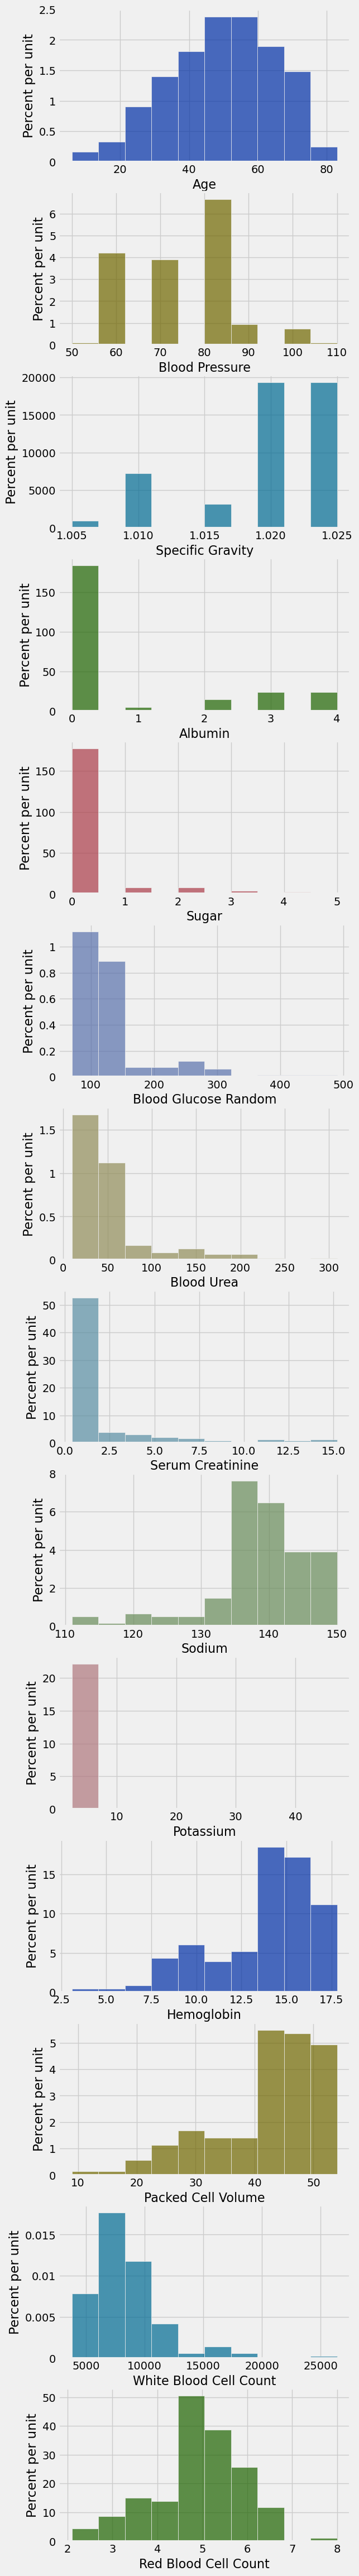

In [14]:
ckd_num.hist(overlay = False)

***QUESTION: Which variables are***  
* Symmetric:
* Skewed Left: 
* Skewed Right: 
* Other:

## 2.3 Measures of Center and Spread

Measures of Center: mean, median, and mode

Notations for means:
 * $\mu$: population mean: the true mean (may not be known - what we're trying to approximate)
 * $\bar{x}$: sample mean: mean from the data - used to approximate $\mu$

Measures of Spread: Range, IQR, Variance, Standard Deviation.
 * $Range = max - min$: spread of all of the data. Postive distance
 * $IQR = Q3 - Q1$: spread of the middle 50%. Positive distance
 * Variance: How the data varies from the mean. Positive distance. Squared value to make sure negative and positive distances from the mean don't cancel out. (used primarily for calculations). Squared units. <br>
    * Population Variance: $\sigma^2=\dfrac{\Sigma(x-\mu)^2}{N}$ 
        * Where $x$ is a data point, $\mu$ is population mean, $N$ is population size

    * Sample Variance: $s^2=\dfrac{\Sigma(x-\bar{x})^2}{n-1}$ 
        * Where $x$ is a data point, $\bar{x}$ is sample mean, $n$ is sample size

 * Standard Deviation: How the data varies from the mean. Positive or Negative distance. Square Root of variance to show which direction from the mean the values lie. Used for decribing the data since the units match the data.
    * Population Standard Deviation: $\sigma=\sqrt{\sigma^2}$
    * Sample Standard Deviation: $s =\sqrt{s^2}$

### Find the measures of center for our data


In [17]:
# Find the mean
np.mean(commute.column(column_name))

553.84338584133616

In [20]:
# Find the median
np.median(commute.column(column_name))

499.0

In [27]:
# Find the mode
from scipy import stats
stats.mode(commute.column(column_name))

ModeResult(mode=359, count=381)

In [30]:
# The mode command gives the value of the mode and how many records are at that value. 
# Verify the count using the table. 

commute.where('Duration', 359).num_rows

381

***List our three measures of center:***
 * Mean: 553.8
 * Median: 499.0
 * Mode: 359

***QUESTION: Which is the better measure of center for our data? Why?***

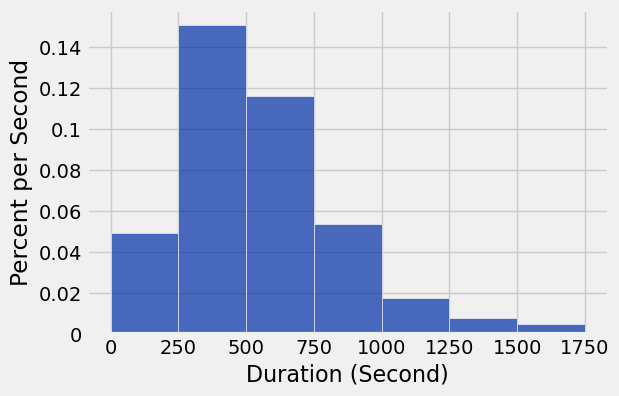

In [13]:
commute.hist('Duration', bins=np.arange(0, 1800, 250), unit='Second')

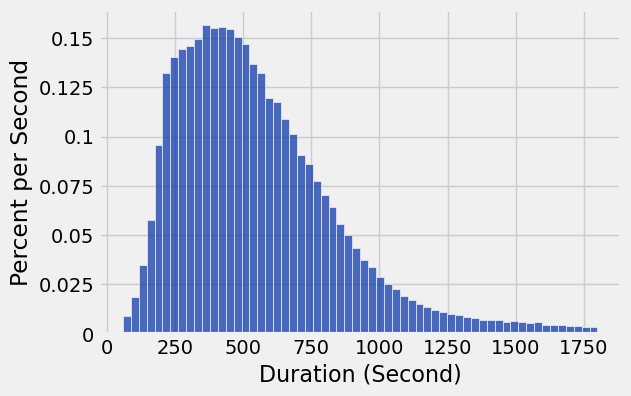

In [14]:
commute.hist('Duration', bins=60, unit='Second')

***Compare the Histograms***

Describe the new histogram.

***QUESTION: What changed?***

***QUESTION: Which display of the three would you prefer to view to interpret this data set? Why?***